# SANC — Member 3: End-to-end enhancement & quantitative evaluation

**Scope (Tasks 4 & 5):** run the trained models, generate enhanced images, and compare
Gaussian-noise DDPM, fixed blue-noise DDPM and the current SANC DDPM against classical
(brightness, CLAHE, Retinex) and CNN baselines on the **same 410 held-out test images**, using
PSNR, SSIM, LPIPS, masked PSNR, boundary-F1, Dice/IoU (fixed downstream segmenters) and paired statistics.

**Rules this notebook follows**
* Test images are used **only** for the final numbers. Sampler settings are chosen on the validation split.
* All diffusion variants share one architecture, one training recipe and one sampler; only the noise differs.
* Every table reports N. Metrics are computed on outputs clipped to [0,1] (raw out-of-range fraction is logged).
* Nothing here claims SANC wins; the notebook reports whatever is measured, with confidence intervals.

**Run order:** top to bottom. Set `CFG["QUICK"]=True` first for a ~10 minute smoke test, then `False` for the real run.

## 0. Setup
Runtime ▸ Change runtime type ▸ **T4 GPU** before running. Needs the Drive folder `SANC/` with `datasets/`, `models/best_unet_saliency.pth` and `models/reverse_diffusion_model.pth`.

In [31]:
# --- Colab setup (safe to re-run) ---
import importlib, subprocess, sys
for pkg in ["lpips", "scikit-image", "tabulate", "opencv-python-headless"]:
    try: importlib.import_module({"scikit-image": "skimage", "opencv-python-headless": "cv2"}.get(pkg, pkg))
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - using local paths from CFG['ROOT'].")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
# --- Imports & global helpers ---------------------------------------------------------
import os, sys, math, json, time, random, warnings, shutil, zipfile
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from scipy import stats as sstats
from scipy.ndimage import binary_erosion, distance_transform_edt
from skimage.metrics import structural_similarity
warnings.filterwarnings("ignore", category=UserWarning)

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

def new_gen(seed, device=None):
    g = torch.Generator(device=device or DEV)
    g.manual_seed(int(seed))
    return g

In [33]:
# --- Configuration --------------------------------------------------------------------
CFG = dict(
    ROOT="/content/drive/MyDrive/SANC",       # Drive folder that contains datasets/ models/ results/
    OUT_SUBDIR="results/member3",
    CACHE="/content/sanc_cache_128.npz",       # local (fast) cache of resized images
    SEED=42, IMG=128,
    # diffusion schedule — identical to Member 1's notebook (cell 187)
    T=100, BETA_START=1e-4, BETA_END=0.02,
    # training recipe — identical to Member 1's notebook (cell 235)
    BATCH=8, EPOCHS=10, LR=1e-4, WD=1e-4,
    CNN_EPOCHS=10, CNN_LR=2e-4, SEG_EPOCHS=8, SEG_LR=1e-4,
    REV_BASE=64, CNN_BASE=32, SEG_BASE=64,     # SEG_BASE must stay 64 to load best_unet_saliency.pth
    EVAL_BATCH=32,
    # sampler (selected on VALIDATION images only)
    DDIM_STEPS=25, T0_GRID=[99, 75, 50, 25, 10], SELECT_N=48, SELECT_SET="val",
    RETRAIN_SANC=False,     # True = also retrain SANC with exactly this recipe (cleanest matched comparison)
    RUN_LEGACY=True,        # also run Member 1's two original DDPM samplers on the SANC checkpoint
    BOUNDARY_TOL=2,         # pixels (at 128x128) for boundary F1
    N_BOOT=10000,
    QUICK=False, QUICK_N=(8, 8, 24),   # (train, val, test) images per dataset in QUICK mode
)

## 1. Model definitions
The next two cells contain **verbatim copies** of the classes from `SANC_Preprocessing_Integration.ipynb`
(cells 206-209 and 233) so the saved checkpoints load without any key mismatch.

In [34]:
# ---- verbatim from SANC_Preprocessing_Integration.ipynb, cells 206-209 ----
# ============================================================
# REVERSE DIFFUSION — TIME EMBEDDING
# ============================================================
# ============================================================
# REVERSE DIFFUSION — IMPORTS
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

class TimeEmbedding(nn.Module):

    def __init__(self, embedding_dim):
        super().__init__()

        self.embedding_dim = embedding_dim

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, embedding_dim * 2),
            nn.SiLU(),
            nn.Linear(embedding_dim * 2, embedding_dim)
        )

    def forward(self, t):

        half_dim = self.embedding_dim // 2

        exponent = (
            -np.log(10000)
            * torch.arange(
                half_dim,
                device=t.device
            )
            / (half_dim - 1)
        )

        embedding = t.float().unsqueeze(1) * torch.exp(exponent)

        embedding = torch.cat(
            [
                torch.sin(embedding),
                torch.cos(embedding)
            ],
            dim=1
        )

        return self.mlp(embedding)

# ============================================================
# TIME-CONDITIONED RESIDUAL BLOCK
# ============================================================

class TimeResBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            3,
            padding=1
        )

        self.norm1 = nn.BatchNorm2d(
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            3,
            padding=1
        )

        self.norm2 = nn.BatchNorm2d(
            out_channels
        )

        self.time_proj = nn.Linear(
            time_dim,
            out_channels
        )

        self.activation = nn.SiLU()

        self.skip = (
            nn.Conv2d(
                in_channels,
                out_channels,
                1
            )
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t_embedding):

        h = self.conv1(x)
        h = self.norm1(h)

        time_term = self.time_proj(
            t_embedding
        ).unsqueeze(-1).unsqueeze(-1)

        h = self.activation(
            h + time_term
        )

        h = self.norm2(
            self.conv2(h)
        )

        h = h + self.skip(x)

        return self.activation(h)

# ============================================================
# ATTENTION-BASED FEATURE FUSION
# ============================================================

class AttentionFusion(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Conv2d(
                channels * 2,
                channels,
                1
            ),
            nn.SiLU(),

            nn.Conv2d(
                channels,
                2,
                1
            ),

            nn.Softmax(dim=1)
        )

        self.output = nn.Conv2d(
            channels,
            channels,
            3,
            padding=1
        )

    def forward(
        self,
        illumination_features,
        detail_features
    ):

        combined = torch.cat(
            [
                illumination_features,
                detail_features
            ],
            dim=1
        )

        weights = self.attention(
            combined
        )

        illumination_weight = (
            weights[:, 0:1]
        )

        detail_weight = (
            weights[:, 1:2]
        )

        fused = (
            illumination_weight
            * illumination_features
            +
            detail_weight
            * detail_features
        )

        return self.output(fused)

# ============================================================
# CONDITIONAL DUAL-BRANCH REVERSE DIFFUSION U-NET
# ============================================================
#
# Input:
#   x_t       : noisy diffusion image      [B, 3, H, W]
#   low_light : low-light conditioning     [B, 3, H, W]
#   saliency  : predicted saliency map     [B, 1, H, W]
#   t         : diffusion timestep         [B]
#
# Total input channels = 3 + 3 + 1 = 7
#
# Output:
#   predicted colored noise               [B, 3, H, W]
#
# Architecture:
#   Shared encoder
#       ↓
#   Illumination branch ─┐
#                        ├→ Attention Fusion → Noise prediction
#   Detail branch ───────┘
# ============================================================


class DualBranchReverseUNet(nn.Module):

    def __init__(
        self,
        in_channels=7,
        base_channels=64,
        time_dim=128
    ):
        super().__init__()

        # ----------------------------------------------------
        # Time embedding
        # ----------------------------------------------------

        self.time_embedding = TimeEmbedding(time_dim)

        # ----------------------------------------------------
        # SHARED ENCODER
        # ----------------------------------------------------
        #
        # 7 → 64 → 128 → 256 → 512
        #

        self.enc1 = TimeResBlock(
            in_channels,
            base_channels,
            time_dim
        )

        self.enc2 = TimeResBlock(
            base_channels,
            base_channels * 2,
            time_dim
        )

        self.enc3 = TimeResBlock(
            base_channels * 2,
            base_channels * 4,
            time_dim
        )

        self.bottleneck = TimeResBlock(
            base_channels * 4,
            base_channels * 8,
            time_dim
        )

        # ----------------------------------------------------
        # UPSAMPLING
        # ----------------------------------------------------
        #
        # 512 → 256
        # 256 → 128
        # 128 → 64
        #

        self.up3 = nn.ConvTranspose2d(
            base_channels * 8,
            base_channels * 4,
            kernel_size=2,
            stride=2
        )

        self.up2 = nn.ConvTranspose2d(
            base_channels * 4,
            base_channels * 2,
            kernel_size=2,
            stride=2
        )

        self.up1 = nn.ConvTranspose2d(
            base_channels * 2,
            base_channels,
            kernel_size=2,
            stride=2
        )

        # ====================================================
        # ILLUMINATION RESTORATION BRANCH
        # ====================================================
        #
        # At decoder level 3:
        #   up3 = 256 channels
        #   skip e3 = 256 channels
        #   concat = 512 channels
        #

        self.illum_dec3 = TimeResBlock(
            base_channels * 8,
            base_channels * 4,
            time_dim
        )

        # Level 2:
        #   up2 = 128
        #   skip e2 = 128
        #   concat = 256

        self.illum_dec2 = TimeResBlock(
            base_channels * 4,
            base_channels * 2,
            time_dim
        )

        # Level 1:
        #   up1 = 64
        #   skip e1 = 64
        #   concat = 128

        self.illum_dec1 = TimeResBlock(
            base_channels * 2,
            base_channels,
            time_dim
        )

        # ====================================================
        # DETAIL PRESERVATION BRANCH
        # ====================================================

        self.detail_dec3 = TimeResBlock(
            base_channels * 8,
            base_channels * 4,
            time_dim
        )

        self.detail_dec2 = TimeResBlock(
            base_channels * 4,
            base_channels * 2,
            time_dim
        )

        self.detail_dec1 = TimeResBlock(
            base_channels * 2,
            base_channels,
            time_dim
        )

        # ----------------------------------------------------
        # ATTENTION-BASED FUSION
        # ----------------------------------------------------

        self.fusion = AttentionFusion(
            base_channels
        )

        # ----------------------------------------------------
        # FINAL NOISE PREDICTION
        # ----------------------------------------------------

        self.output = nn.Conv2d(
            base_channels,
            3,
            kernel_size=1
        )

    def forward(
        self,
        x_t,
        low_light,
        saliency,
        t
    ):

        # ----------------------------------------------------
        # Combine diffusion state + conditioning
        # ----------------------------------------------------

        x = torch.cat(
            [
                x_t,
                low_light,
                saliency
            ],
            dim=1
        )

        # x = [B, 7, H, W]

        # ----------------------------------------------------
        # Time embedding
        # ----------------------------------------------------

        t_emb = self.time_embedding(t)

        # ----------------------------------------------------
        # SHARED ENCODER
        # ----------------------------------------------------

        e1 = self.enc1(
            x,
            t_emb
        )

        # [B, 64, H, W]

        e2 = self.enc2(
            F.avg_pool2d(e1, 2),
            t_emb
        )

        # [B, 128, H/2, W/2]

        e3 = self.enc3(
            F.avg_pool2d(e2, 2),
            t_emb
        )

        # [B, 256, H/4, W/4]

        b = self.bottleneck(
            F.avg_pool2d(e3, 2),
            t_emb
        )

        # [B, 512, H/8, W/8]

        # ====================================================
        # ILLUMINATION BRANCH
        # ====================================================

        u3_i = self.up3(b)

        # [B, 256, H/4, W/4]

        u3_i = torch.cat(
            [
                u3_i,
                e3
            ],
            dim=1
        )

        # [B, 512, H/4, W/4]

        illum3 = self.illum_dec3(
            u3_i,
            t_emb
        )

        # [B, 256, H/4, W/4]

        u2_i = self.up2(illum3)

        # [B, 128, H/2, W/2]

        u2_i = torch.cat(
            [
                u2_i,
                e2
            ],
            dim=1
        )

        # [B, 256, H/2, W/2]

        illum2 = self.illum_dec2(
            u2_i,
            t_emb
        )

        # [B, 128, H/2, W/2]

        u1_i = self.up1(illum2)

        # [B, 64, H, W]

        u1_i = torch.cat(
            [
                u1_i,
                e1
            ],
            dim=1
        )

        # [B, 128, H, W]

        illum1 = self.illum_dec1(
            u1_i,
            t_emb
        )

        # [B, 64, H, W]

        # ====================================================
        # DETAIL BRANCH
        # ====================================================

        u3_d = self.up3(b)

        u3_d = torch.cat(
            [
                u3_d,
                e3
            ],
            dim=1
        )

        detail3 = self.detail_dec3(
            u3_d,
            t_emb
        )

        u2_d = self.up2(detail3)

        u2_d = torch.cat(
            [
                u2_d,
                e2
            ],
            dim=1
        )

        detail2 = self.detail_dec2(
            u2_d,
            t_emb
        )

        u1_d = self.up1(detail2)

        u1_d = torch.cat(
            [
                u1_d,
                e1
            ],
            dim=1
        )

        detail1 = self.detail_dec1(
            u1_d,
            t_emb
        )

        # ====================================================
        # ATTENTION FUSION
        # ====================================================

        fused = self.fusion(
            illum1,
            detail1
        )

        # [B, 64, H, W]

        # ====================================================
        # PREDICT DIFFUSION NOISE
        # ====================================================

        predicted_noise = self.output(
            fused
        )

        # [B, 3, H, W]

        return predicted_noise

In [35]:
# ---- verbatim from SANC_Preprocessing_Integration.ipynb, cell 233 (the version used for training) ----
# ============================================================
# RESTORE SANC NOISE COLORING MODULE
# ============================================================

class SANCNoiseColoring(nn.Module):

    def __init__(self, saliency_power=1.0):
        super().__init__()
        self.saliency_power = saliency_power

    def _frequency_bands(self, H, W, device):

        fy = torch.fft.fftfreq(
            H,
            device=device
        )

        fx = torch.fft.fftfreq(
            W,
            device=device
        )

        yy, xx = torch.meshgrid(
            fy,
            fx,
            indexing="ij"
        )

        radius = torch.sqrt(
            xx ** 2 + yy ** 2
        )

        radius = radius / (
            radius.max() + 1e-8
        )

        # Smooth frequency bands
        low = torch.exp(
            -0.5 * (
                (radius - 0.15) / 0.20
            ) ** 2
        )

        mid = torch.exp(
            -0.5 * (
                (radius - 0.45) / 0.20
            ) ** 2
        )

        high = torch.exp(
            -0.5 * (
                (radius - 0.80) / 0.20
            ) ** 2
        )

        # Normalize so bands approximately partition energy
        total = low + mid + high + 1e-8

        low = low / total
        mid = mid / total
        high = high / total

        return low, mid, high

    def forward(self, noise, saliency):

        B, C, H, W = noise.shape

        # ----------------------------------------------------
        # Resize saliency if necessary
        # ----------------------------------------------------

        saliency = F.interpolate(
            saliency,
            size=(H, W),
            mode="bilinear",
            align_corners=False
        )

        saliency = torch.clamp(
            saliency,
            0.0,
            1.0
        )

        saliency = saliency ** self.saliency_power

        # ----------------------------------------------------
        # Frequency bands
        # ----------------------------------------------------

        low_band, mid_band, high_band = (
            self._frequency_bands(
                H,
                W,
                noise.device
            )
        )

        low_band = low_band[None, None, :, :]
        mid_band = mid_band[None, None, :, :]
        high_band = high_band[None, None, :, :]

        # ----------------------------------------------------
        # FFT of Gaussian noise
        # ----------------------------------------------------

        noise_fft = torch.fft.fft2(
            noise
        )

        # ----------------------------------------------------
        # Extract frequency components
        # ----------------------------------------------------

        low_fft = (
            noise_fft * low_band
        )

        mid_fft = (
            noise_fft * mid_band
        )

        high_fft = (
            noise_fft * high_band
        )

        # ----------------------------------------------------
        # Convert back to spatial domain
        # ----------------------------------------------------

        low_noise = torch.fft.ifft2(
            low_fft
        ).real

        mid_noise = torch.fft.ifft2(
            mid_fft
        ).real

        high_noise = torch.fft.ifft2(
            high_fft
        ).real

        # ----------------------------------------------------
        # Saliency-dependent spectral weighting
        # ----------------------------------------------------
        #
        # Background:
        #   low = 0.55
        #   mid = 0.30
        #   high = 0.15
        #
        # High saliency:
        #   low = 0.20
        #   mid = 0.30
        #   high = 0.50
        #

        low_weight = (
            0.55
            - 0.35 * saliency
        )

        mid_weight = (
            torch.ones_like(saliency)
            * 0.30
        )

        high_weight = (
            0.15
            + 0.35 * saliency
        )

        # ----------------------------------------------------
        # Spatially adaptive spectral mixture
        # ----------------------------------------------------

        colored_noise = (
            low_weight * low_noise
            + mid_weight * mid_noise
            + high_weight * high_noise
        )

        # ----------------------------------------------------
        # Per-sample/channel normalization
        # ----------------------------------------------------

        mean = colored_noise.mean(
            dim=(2, 3),
            keepdim=True
        )

        std = colored_noise.std(
            dim=(2, 3),
            keepdim=True
        )

        colored_noise = (
            colored_noise - mean
        ) / (
            std + 1e-8
        )

        return colored_noise

In [36]:
# --- Saliency / segmentation U-Net (same layer names as the notebook's OriginalUNet, cell 185) ---
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class OriginalUNet(nn.Module):
    """Sigmoid-output U-Net. base=64 reproduces the checkpoint layout exactly.
    NOTE: the reverse model was trained with THIS (sigmoid) saliency, not the logit-output `UNet` class."""
    def __init__(self, in_channels=3, out_channels=1, base=64):
        super().__init__()
        b = base
        self.enc1 = DoubleConv(in_channels, b); self.enc2 = DoubleConv(b, 2*b)
        self.enc3 = DoubleConv(2*b, 4*b);       self.enc4 = DoubleConv(4*b, 8*b)
        self.pool = nn.MaxPool2d(2, 2)
        self.bottleneck = DoubleConv(8*b, 16*b)
        self.up4 = nn.ConvTranspose2d(16*b, 8*b, 2, 2); self.dec4 = DoubleConv(16*b, 8*b)
        self.up3 = nn.ConvTranspose2d(8*b, 4*b, 2, 2);  self.dec3 = DoubleConv(8*b, 4*b)
        self.up2 = nn.ConvTranspose2d(4*b, 2*b, 2, 2);  self.dec2 = DoubleConv(4*b, 2*b)
        self.up1 = nn.ConvTranspose2d(2*b, b, 2, 2);    self.dec1 = DoubleConv(2*b, b)
        self.output = nn.Conv2d(b, out_channels, 1)
    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1)); e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1)); d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1)); d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.output(d1))

class EnhanceCNN(nn.Module):
    """Supervised CNN baseline: low-light -> normal-light regression (3-level U-Net, sigmoid output)."""
    def __init__(self, base=32):
        super().__init__()
        c = base
        self.e1 = DoubleConv(3, c); self.e2 = DoubleConv(c, 2*c); self.e3 = DoubleConv(2*c, 4*c)
        self.pool = nn.MaxPool2d(2, 2)
        self.u2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2); self.d2 = DoubleConv(4*c, 2*c)
        self.u1 = nn.ConvTranspose2d(2*c, c, 2, 2);   self.d1 = DoubleConv(2*c, c)
        self.out = nn.Conv2d(c, 3, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); e3 = self.e3(self.pool(e2))
        d2 = self.d2(torch.cat([self.u2(e3), e2], 1)); d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return torch.sigmoid(self.out(d1))

## 2. Noise generators, diffusion schedule, samplers
All three noises are standardised per sample/channel to zero mean / unit variance (exactly as SANC does), so the
comparison isolates **spectral/spatial structure**, not noise power.

* **Gaussian** – white noise (standard DDPM).
* **Fixed blue** – white noise × √f radial amplitude (power ∝ f, i.e. blue), saliency-independent. This is a simple
  spectral construction, *not* the authors' implementation of "Blue Noise for Diffusion Models".
* **SANC** – Member 1's `SANCNoiseColoring` (saliency-weighted low/mid/high band mixture).

**Sampler.** The notebook's DDPM sampler starts from N(0, I), but with T=100 and ᾱ_T=0.3636 the training-time
x_T still contains 0.60·x₀, and SANC noise is not white — so that update is not justified (Member 1's open task).
Until Member 1 supplies a derived sampler, this notebook uses a **deterministic DDIM-style (η=0) sampler** that only
relies on the training marginal x_t = √ᾱ_t·x₀ + √(1-ᾱ_t)·ε (valid for any noise law the net was trained on), started
at an intermediate step t₀ from the low-light image (SDEdit-style). t₀ is chosen on validation data. Member 1's
original two samplers are kept as clearly-labelled reference rows.

In [37]:
def _standardise(z):
    m = z.mean(dim=(2, 3), keepdim=True)
    s = z.std(dim=(2, 3), keepdim=True)
    return (z - m) / (s + 1e-8)

def blue_colour(z):
    """White -> blue: amplitude ∝ sqrt(radial frequency) (power ∝ f); then per-sample/channel standardisation."""
    B, C, H, W = z.shape
    fy = torch.fft.fftfreq(H, device=z.device); fx = torch.fft.fftfreq(W, device=z.device)
    yy, xx = torch.meshgrid(fy, fx, indexing="ij")
    r = torch.sqrt(xx ** 2 + yy ** 2); r = r / r.max()
    amp = torch.sqrt(r)[None, None]
    out = torch.fft.ifft2(torch.fft.fft2(z) * amp).real
    return _standardise(out)

def make_noise(kind, shape, saliency, gen=None, sanc=None):
    dev = saliency.device
    z = torch.randn(shape, generator=gen, device=dev) if gen is not None else torch.randn(shape, device=dev)
    if kind == "gaussian":
        return z
    if kind == "blue":
        return blue_colour(z)
    if kind == "sanc":
        return sanc(z, saliency)
    raise ValueError(kind)

class Schedule:
    def __init__(self, T, b0, b1, device):
        self.T = T
        self.betas = torch.linspace(b0, b1, T, device=device)
        self.alphas = 1.0 - self.betas
        self.ab = torch.cumprod(self.alphas, 0)
        self.ab_prev = torch.cat([torch.ones(1, device=device), self.ab[:-1]])
        self.post_var = self.betas * (1.0 - self.ab_prev) / (1.0 - self.ab)

def q_sample(x0, t, noise, sched):
    ab = sched.ab[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1.0 - ab).sqrt() * noise

@torch.no_grad()
def ddim_sample(model, low, sal, kind, sanc, sched, t0, n_steps, gen=None, clip_x0=True, init="lowlight"):
    """Deterministic (eta=0) sampler, started at step t0 from the low-light image."""
    model.eval()
    B = low.shape[0]
    ts = torch.linspace(t0, 0, max(2, n_steps)).round().long().tolist()
    ts = sorted(set(ts), reverse=True)
    eps0 = make_noise(kind, low.shape, sal, gen, sanc)
    x0_init = low if init == "lowlight" else torch.zeros_like(low)
    ab0 = sched.ab[t0]
    x = ab0.sqrt() * x0_init + (1.0 - ab0).sqrt() * eps0
    for i, t in enumerate(ts):
        tt = torch.full((B,), t, device=low.device, dtype=torch.long)
        eps = model(x, low, sal, tt)
        ab = sched.ab[t]
        x0 = (x - (1.0 - ab).sqrt() * eps) / ab.sqrt()
        if clip_x0:
            x0 = x0.clamp(0.0, 1.0)
            eps = (x - ab.sqrt() * x0) / (1.0 - ab).sqrt()
        if i + 1 < len(ts):
            abp = sched.ab[ts[i + 1]]
            x = abp.sqrt() * x0 + (1.0 - abp).sqrt() * eps
        else:
            x = x0
    return x

@torch.no_grad()
def legacy_ddpm(model, low, sal, sched, start="noise", gen=None):
    """Member 1's original DDPM ancestral sampler (notebook cell 271): white-noise injection, no clipping."""
    model.eval()
    B = low.shape[0]
    x = torch.randn(low.shape, generator=gen, device=low.device) if start == "noise" else low.clone()
    for step in reversed(range(sched.T)):
        t = torch.full((B,), step, device=low.device, dtype=torch.long)
        eps = model(x, low, sal, t)
        mean = (x - sched.betas[step] / (1.0 - sched.ab[step]).sqrt() * eps) / sched.alphas[step].sqrt()
        if step > 0:
            x = mean + sched.post_var[step].sqrt() * torch.randn(low.shape, generator=gen, device=low.device)
        else:
            x = mean
    return x

## 3. Data: rebuild the 2,300-image table and cache resized tensors
Path logic mirrors Member 1's notebook (cells 226 and 278). Preprocessing is identical to `SANCMedicalDataset`:
bilinear resize for images, nearest for masks, mask = (value > 0). Cached once in RAM/local disk for speed.

In [38]:
def build_dataframe(root):
    R = Path(root) / "datasets"
    # --- HAM10000 (relative paths in metadata.csv -> actual folders, cell 226)
    ham_root = R / "ham" / "HAM preprocessing"
    ham = pd.read_csv(ham_root / "metadata.csv")
    fn = ham["image_id"].astype(str).apply(lambda x: Path(x).stem + ".png")
    HAM = pd.DataFrame({
        "filename": fn,
        "original": fn.apply(lambda x: str(ham_root / "images" / "images" / x)),
        "low_light": fn.apply(lambda x: str(ham_root / "low_light" / "low_light" / x)),
        "mask": fn.apply(lambda x: str(ham_root / "masks" / "masks" / x)),
        "dataset": "HAM10000", "split": ham["split"].astype(str).str.strip().str.lower()})
    # --- ORIGA (cell 278)
    o_root = R / "ORIGA_processed" / "integration"
    og = pd.read_csv(o_root / "ORIGA_common_metadata.csv")
    ofn = og["filename"].astype(str).apply(lambda x: Path(x).name)
    ORIGA = pd.DataFrame({
        "filename": ofn,
        "original": ofn.apply(lambda x: str(o_root / "images" / x)),
        "low_light": ofn.apply(lambda x: str(o_root / "low_light" / x)),
        "mask": ofn.apply(lambda x: str(o_root / "masks" / x)),
        "dataset": "ORIGA", "split": og["split"].astype(str).str.strip().str.lower()})
    # --- Kvasir-SEG (train/val/test CSVs, cell 278)
    k_root = R / "kvasir"; meta = R / "metadata"
    parts = []
    for csvn, sp in [("kvasir_train.csv", "train"), ("kvasir_val.csv", "val"), ("kvasir_test.csv", "test")]:
        d = pd.read_csv(meta / csvn)
        col = next(c for c in ["filename", "image", "image_id", "id"] if c in d.columns)
        f = d[col].astype(str).apply(lambda x: Path(x).name)
        parts.append(pd.DataFrame({
            "filename": f,
            "original": f.apply(lambda x: str(k_root / "original" / x)),
            "low_light": f.apply(lambda x: str(k_root / "low_light" / x)),
            "mask": f.apply(lambda x: str(k_root / "masks" / x)),
            "dataset": "Kvasir-SEG", "split": sp}))
    KV = pd.concat(parts, ignore_index=True)
    return pd.concat([KV, ORIGA, HAM], ignore_index=True)

def _open_rgb(path, img):
    try:
        return Image.open(path).convert("RGB").resize((img, img), Image.Resampling.BILINEAR)
    except Exception as e:
        raise RuntimeError(f"Cannot read image file: {path}  ({e})")

def _load_one(row, img):
    lo = _open_rgb(row["low_light"], img)
    og = _open_rgb(row["original"], img)
    try:
        mk = (np.asarray(Image.open(row["mask"]).convert("L").resize((img, img), Image.Resampling.NEAREST)) > 0).astype(np.uint8)[None]
    except Exception:
        # e.g. the 0-byte Kvasir mask cju89y9h0puti0818i5yw29e6.jpg: keep the image for image metrics, no mask -> excluded from mask metrics
        mk = np.zeros((1, img, img), np.uint8)
    return (np.asarray(lo, np.uint8).transpose(2, 0, 1), np.asarray(og, np.uint8).transpose(2, 0, 1), mk)

class Store:
    """In-memory uint8 image store. Index with integer positions of `self.df`."""
    def __init__(self, df, low, orig, mask):
        self.df = df.reset_index(drop=True)
        self.low, self.orig, self.mask = low, orig, mask
        self.has_mask = mask.reshape(len(mask), -1).sum(1) > 0
    def __len__(self):
        return len(self.df)
    def get(self, idx):
        idx = np.asarray(idx)
        f = lambda a: torch.from_numpy(a[idx]).float().div(255.0).to(DEV)
        return dict(low=f(self.low), ref=f(self.orig), mask=torch.from_numpy(self.mask[idx]).float().to(DEV),
                    has_mask=torch.from_numpy(self.has_mask[idx]).to(DEV))

def quick_subset(df, n_train, n_val, n_test):
    keep = []
    for (ds, sp), g in df.groupby(["dataset", "split"], sort=False):
        n = {"train": n_train, "val": n_val, "test": n_test}[sp]
        keep.append(g.head(n))
    return pd.concat(keep, ignore_index=True)

def cache_store(df, img=128, cache_path=None):
    df = df.reset_index(drop=True)
    if cache_path and Path(cache_path).exists():
        z = np.load(cache_path, allow_pickle=True)
        if list(z["names"]) == (df["dataset"] + "|" + df["filename"] + "|" + df["split"]).tolist():
            print("Loaded image cache:", cache_path)
            return Store(df, z["low"], z["orig"], z["mask"])
    from concurrent.futures import ThreadPoolExecutor
    rows = [r for _, r in df.iterrows()]
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(lambda r: _load_one(r, img), rows))
    low = np.stack([r[0] for r in res]); orig = np.stack([r[1] for r in res]); mask = np.stack([r[2] for r in res])
    if cache_path:
        np.savez(cache_path, low=low, orig=orig, mask=mask,
                 names=np.array((df["dataset"] + "|" + df["filename"] + "|" + df["split"]).tolist()))
    return Store(df, low, orig, mask)

def audit_data(store):
    """Counts, mask availability and the low-light degradation strength per dataset (flags protocol differences)."""
    df = store.df.copy()
    df["has_mask"] = store.has_mask
    df["low_mean"] = store.low.reshape(len(df), -1).mean(1) / 255.0
    df["ref_mean"] = store.orig.reshape(len(df), -1).mean(1) / 255.0
    g = df.groupby(["dataset", "split"]).agg(N=("filename", "size"), with_mask=("has_mask", "sum"),
                                              low_mean=("low_mean", "mean"), ref_mean=("ref_mean", "mean"))
    g["low/ref brightness"] = g["low_mean"] / g["ref_mean"]
    return g.round(4)

## 4. Classical baselines (brightness, CLAHE, Retinex)

In [39]:
def brightness_baseline(low, gain=1.8):
    return (gain * low).clamp(0, 1)

def clahe_baseline(low, clip=3.0, tile=8):
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    out = []
    for im in (low.clamp(0, 1).cpu().numpy().transpose(0, 2, 3, 1) * 255).round().astype(np.uint8):
        lab = cv2.cvtColor(im, cv2.COLOR_RGB2LAB)
        lab[..., 0] = cl.apply(lab[..., 0])
        out.append(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))
    return torch.from_numpy(np.stack(out).transpose(0, 3, 1, 2)).float().div(255).to(low.device)

def retinex_baseline(low, sigmas=(4, 12, 32), lo_p=1.0, hi_p=99.0):
    """Multi-scale Retinex per RGB channel + percentile stretch (uses only the input image)."""
    out = []
    for im in low.clamp(0, 1).cpu().numpy().transpose(0, 2, 3, 1):
        x = im.astype(np.float32) * 255.0 + 1.0
        msr = np.zeros_like(x)
        for s in sigmas:
            msr += np.log(x) - np.log(cv2.GaussianBlur(x, (0, 0), s) + 1e-6)
        msr /= len(sigmas)
        res = np.empty_like(msr)
        for c in range(3):
            a, b = np.percentile(msr[..., c], [lo_p, hi_p])
            res[..., c] = np.clip((msr[..., c] - a) / (b - a + 1e-6), 0, 1)
        out.append(res)
    return torch.from_numpy(np.stack(out).transpose(0, 3, 1, 2)).float().to(low.device)

## 5. Metrics and statistics

In [40]:
def get_lpips():
    try:
        import lpips
        return lpips.LPIPS(net="alex", verbose=False).to(DEV).eval()
    except Exception as e:
        print("LPIPS unavailable ->", repr(e)[:150], "| LPIPS will be NaN. In Colab run: !pip -q install lpips")
        return None

def psnr_t(a, b):
    mse = ((a - b) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return 10 * torch.log10(1.0 / mse)

def masked_psnr(a, b, m):
    """PSNR restricted to mask pixels (m=1) -> lesion/optic-disc/polyp fidelity. NaN if mask is empty."""
    out = []
    for x, y, mk in zip(a, b, m):
        n = mk.sum() * 3
        out.append(float("nan") if n < 1 else float(10 * torch.log10(1.0 / (((x - y) ** 2 * mk).sum() / n).clamp_min(1e-10))))
    return out

def _boundary(m):
    m = m.astype(bool)
    return m & ~binary_erosion(m, border_value=0)

def boundary_f1(pred, gt, tol=2):
    bp, bg = _boundary(pred), _boundary(gt)
    if bg.sum() == 0:
        return float("nan")
    if bp.sum() == 0:
        return 0.0
    dg = distance_transform_edt(~bg); dp = distance_transform_edt(~bp)
    prec = (dg[bp] <= tol).mean(); rec = (dp[bg] <= tol).mean()
    return float(2 * prec * rec / (prec + rec + 1e-12))

def dice_iou(pred, gt):
    p = pred.astype(bool); g = gt.astype(bool)
    inter = (p & g).sum(); ps, gs = p.sum(), g.sum()
    if gs == 0:
        return float("nan"), float("nan")
    return float(2 * inter / (ps + gs + 1e-9)), float(inter / (ps + gs - inter + 1e-9))

def dice_pair(a, b):
    a = a.astype(bool); b = b.astype(bool)
    d = a.sum() + b.sum()
    return float("nan") if d == 0 else float(2 * (a & b).sum() / d)

def paired_stats(df, a, b, metric, n_boot=10000, seed=0):
    """Paired comparison a - b on identical images: mean diff, 95% bootstrap CI, Wilcoxon p, share of images where a is better."""
    key = df["dataset"] + "|" + df["filename"]
    pa = pd.Series(df.loc[df.method == a, metric].values, index=key[df.method == a].values)
    pb = pd.Series(df.loc[df.method == b, metric].values, index=key[df.method == b].values)
    d = (pa - pb).dropna()
    n = len(d)
    if n < 3:
        return dict(a=a, b=b, metric=metric, n=n, mean_diff=np.nan, ci_lo=np.nan, ci_hi=np.nan, wilcoxon_p=np.nan, frac_a_better=np.nan)
    rng = np.random.default_rng(seed)
    boots = d.values[rng.integers(0, n, (n_boot, n))].mean(1)
    try:
        p = float(sstats.wilcoxon(d.values).pvalue) if np.any(d.values != 0) else 1.0
    except Exception:
        p = np.nan
    return dict(a=a, b=b, metric=metric, n=n, mean_diff=float(d.mean()), ci_lo=float(np.percentile(boots, 2.5)),
                ci_hi=float(np.percentile(boots, 97.5)), wilcoxon_p=p, frac_a_better=float((d > 0).mean()))

## 6. Setup, checkpoint check, training of matched baselines

In [41]:
NOISE_OF = {"sanc": "sanc", "sanc_retrained": "sanc", "gaussian": "gaussian", "blue": "blue"}
NAME_OF = {"sanc": "DDPM-SANC (Member 1 ckpt)", "sanc_retrained": "DDPM-SANC (retrained)",
           "gaussian": "DDPM-Gaussian", "blue": "DDPM-Blue (fixed)"}
LOWER_BETTER = {"LPIPS"}

def _q(cfg):
    """QUICK smoke-test runs save their (1-epoch) models under a different name so the real run never reloads them."""
    return "_quick" if cfg["QUICK"] else ""

def setup(cfg):
    set_seed(cfg["SEED"])
    C = dict(cfg=cfg)
    root = Path(cfg["ROOT"]); out = root / cfg["OUT_SUBDIR"]
    (out / "figures").mkdir(parents=True, exist_ok=True)
    C.update(root=root, out=out, models=root / "models")
    df = build_dataframe(root)
    if cfg["QUICK"]:
        df = quick_subset(df, *[cfg["QUICK_N"][i] for i in range(3)])
    C["store"] = cache_store(df, cfg["IMG"], None if cfg["QUICK"] else cfg["CACHE"])
    s = C["store"]
    sp = s.df["split"].values
    C["idx"] = {k: np.where(sp == k)[0] for k in ["train", "val", "test"]}
    C["sched"] = Schedule(cfg["T"], cfg["BETA_START"], cfg["BETA_END"], DEV)
    C["sanc_mod"] = SANCNoiseColoring(saliency_power=1.0).to(DEV)
    print({k: len(v) for k, v in C["idx"].items()}, "| device:", DEV)
    return C

def _load_ckpt(path):
    ck = torch.load(path, map_location=DEV, weights_only=False)
    return ck["model_state_dict"] if "model_state_dict" in ck else ck

def new_reverse(cfg):
    return DualBranchReverseUNet(in_channels=7, base_channels=cfg["REV_BASE"], time_dim=128).to(DEV)

def load_models(C):
    cfg = C["cfg"]
    sal = OriginalUNet(base=cfg["SEG_BASE"]).to(DEV)
    sal.load_state_dict(_load_ckpt(C["models"] / "best_unet_saliency.pth")); sal.eval()
    rev = new_reverse(cfg)
    rev.load_state_dict(_load_ckpt(C["models"] / "reverse_diffusion_model.pth")); rev.eval()
    C["saliency"] = sal
    C["rev"] = OrderedDict(sanc=rev)
    C["seg"] = OrderedDict(SegLL=sal)          # fixed segmenter #1: Member 1's saliency U-Net (trained on LOW-LIGHT input)
    C["losses"] = {}
    return C

@torch.no_grad()
def checkpoint_gate(C, t=50, thresh=0.05):
    """Regression test: Member 1's notebook (cell 266) measured noise-prediction MSE ~0.0066 at t=50 on a val batch."""
    idx = C["idx"]["val"][:32]
    b = C["store"].get(idx)
    sal = C["saliency"](b["low"])
    g = new_gen(C["cfg"]["SEED"])
    eps = make_noise("sanc", b["low"].shape, sal, g, C["sanc_mod"])
    tt = torch.full((len(idx),), t, device=DEV, dtype=torch.long)
    xt = q_sample(b["ref"], tt, eps, C["sched"])
    mse = F.mse_loss(C["rev"]["sanc"](xt, b["low"], sal, tt), eps).item()
    ok = mse < thresh
    print(f"Checkpoint gate: noise-prediction MSE at t={t} = {mse:.5f}  (reference run ~0.0066)  ->", "PASS" if ok else "FAIL")
    if not ok:
        print("   STOP: wrong/corrupt checkpoint, wrong saliency model (use OriginalUNet with sigmoid), or wrong preprocessing.")
    return mse, ok

def train_diffusion(C, key, resume=True):
    cfg, st = C["cfg"], C["store"]
    path = C["models"] / f"reverse_{key}{_q(cfg)}.pth"
    model = new_reverse(cfg)
    if resume and path.exists():
        ck = torch.load(path, map_location=DEV, weights_only=False)
        model.load_state_dict(ck["model_state_dict"]); model.eval()
        C["losses"][key] = ck.get("losses", [])
        print(f"[{key}] loaded {path.name}")
        return model
    kind = NOISE_OF[key]
    set_seed(cfg["SEED"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=cfg["WD"])
    tr = C["idx"]["train"]; losses = []; bs = cfg["BATCH"]
    C["saliency"].eval()
    for ep in range(cfg["EPOCHS"]):
        model.train(); perm = np.random.permutation(tr); run = 0.0; nb = 0
        for i in range(0, len(perm), bs):
            b = st.get(perm[i:i + bs])
            with torch.no_grad():
                sal = C["saliency"](b["low"])
                eps = make_noise(kind, b["ref"].shape, sal, None, C["sanc_mod"])
            t = torch.randint(0, cfg["T"], (len(b["ref"]),), device=DEV)
            xt = q_sample(b["ref"], t, eps, C["sched"])
            loss = F.mse_loss(model(xt, b["low"], sal, t), eps)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item(); nb += 1
        losses.append(run / nb)
        print(f"[{key}] epoch {ep + 1:02d}/{cfg['EPOCHS']}  loss {losses[-1]:.6f}")
    model.eval()
    torch.save(dict(model_state_dict=model.state_dict(), optimizer_state_dict=opt.state_dict(),
                    num_epochs=cfg["EPOCHS"], losses=losses, noise=kind, seed=cfg["SEED"]), path)
    C["losses"][key] = losses
    return model

def train_cnn(C, resume=True):
    cfg, st = C["cfg"], C["store"]
    path = C["models"] / f"enhance_cnn_baseline{_q(cfg)}.pth"
    m = EnhanceCNN(cfg["CNN_BASE"]).to(DEV)
    if resume and path.exists():
        ck = torch.load(path, map_location=DEV, weights_only=False); m.load_state_dict(ck["model_state_dict"]); m.eval()
        C["losses"]["cnn"] = ck.get("losses", []); print("[cnn] loaded"); return m
    set_seed(cfg["SEED"]); opt = torch.optim.AdamW(m.parameters(), lr=cfg["CNN_LR"], weight_decay=cfg["WD"])
    tr = C["idx"]["train"]; losses = []; bs = cfg["BATCH"]
    for ep in range(cfg["CNN_EPOCHS"]):
        m.train(); perm = np.random.permutation(tr); run = 0.0; nb = 0
        for i in range(0, len(perm), bs):
            b = st.get(perm[i:i + bs])
            loss = F.l1_loss(m(b["low"]), b["ref"])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); run += loss.item(); nb += 1
        losses.append(run / nb); print(f"[cnn] epoch {ep + 1:02d}/{cfg['CNN_EPOCHS']}  L1 {losses[-1]:.5f}")
    m.eval()
    torch.save(dict(model_state_dict=m.state_dict(), losses=losses), path)
    C["losses"]["cnn"] = losses
    return m

def _soft_dice_loss(p, y, eps=1.0):
    inter = (p * y).sum((1, 2, 3)); return 1 - ((2 * inter + eps) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + eps)).mean()

def train_segmenter_normal_light(C, resume=True):
    """Fixed downstream segmenter #2, trained on NORMAL-light train images only (best epoch picked on val originals)."""
    cfg, st = C["cfg"], C["store"]
    path = C["models"] / f"seg_normal_light{_q(cfg)}.pth"
    m = OriginalUNet(base=cfg["SEG_BASE"]).to(DEV)
    if resume and path.exists():
        m.load_state_dict(_load_ckpt(path)); m.eval(); print("[SegNL] loaded"); return m
    set_seed(cfg["SEED"]); opt = torch.optim.Adam(m.parameters(), lr=cfg["SEG_LR"])
    tr = C["idx"]["train"]; va = C["idx"]["val"]; bs = cfg["BATCH"]; best = -1; best_sd = None
    for ep in range(cfg["SEG_EPOCHS"]):
        m.train(); perm = np.random.permutation(tr)
        for i in range(0, len(perm), bs):
            b = st.get(perm[i:i + bs]); x, y = b["ref"], b["mask"]
            if np.random.rand() < 0.5: x, y = x.flip(3), y.flip(3)
            p = m(x); loss = F.binary_cross_entropy(p, y) + _soft_dice_loss(p, y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        m.eval(); ds = []
        with torch.no_grad():
            for i in range(0, len(va), 32):
                b = st.get(va[i:i + 32]); pr = (m(b["ref"]) > 0.5).cpu().numpy(); gt = b["mask"].cpu().numpy()
                ds += [dice_iou(p_[0], g_[0])[0] for p_, g_ in zip(pr, gt)]
        d = float(np.nanmean(ds)); print(f"[SegNL] epoch {ep + 1:02d} val Dice {d:.4f}")
        if d > best: best = d; best_sd = {k: v.clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_sd); m.eval()
    torch.save(dict(model_state_dict=best_sd, val_dice=best), path)
    return m

def train_all(C):
    cfg = C["cfg"]
    C["rev"]["gaussian"] = train_diffusion(C, "gaussian")
    C["rev"]["blue"] = train_diffusion(C, "blue")
    if cfg["RETRAIN_SANC"]:
        C["rev"]["sanc_retrained"] = train_diffusion(C, "sanc_retrained")
    C["cnn"] = train_cnn(C)
    C["seg"]["SegNL"] = train_segmenter_normal_light(C)
    return C

## 7. Sampler selection on VALIDATION images (never on test)

In [42]:
@torch.no_grad()
def select_sampler(C):
    cfg, st = C["cfg"], C["store"]
    pool = C["idx"][cfg["SELECT_SET"]]
    sel_idx = pool[np.linspace(0, len(pool) - 1, min(cfg["SELECT_N"], len(pool))).astype(int)]
    rows, sel = [], {}
    for key, model in C["rev"].items():
        best = (-1e9, None)
        for t0 in cfg["T0_GRID"]:
            steps = min(t0 + 1, cfg["DDIM_STEPS"]); ps = []
            for i in range(0, len(sel_idx), cfg["EVAL_BATCH"]):
                b = st.get(sel_idx[i:i + cfg["EVAL_BATCH"]]); sal = C["saliency"](b["low"])
                g = new_gen(cfg["SEED"] + 1000 + i)
                out = ddim_sample(model, b["low"], sal, NOISE_OF[key], C["sanc_mod"], C["sched"], t0, steps, g).clamp(0, 1)
                ps += psnr_t(out, b["ref"]).tolist()
            m = float(np.mean(ps)); rows.append(dict(model=NAME_OF[key], t0=t0, ddim_steps=steps, val_PSNR=m, n=len(sel_idx)))
            if m > best[0]: best = (m, t0, steps)
        sel[key] = dict(t0=best[1], steps=best[2], val_PSNR=best[0])
        print(f"[{NAME_OF[key]}] selected t0={best[1]} ({best[2]} DDIM steps)  val PSNR {best[0]:.3f}")
    C["sel"] = sel; C["sel_table"] = pd.DataFrame(rows)
    C["sel_table"].to_csv(C["out"] / "sampler_selection_val.csv", index=False)
    return C

## 8. Evaluation on the held-out test split

In [43]:
SEG_KEYS = ["SegNL", "SegLL"]

def build_methods(C):
    cfg = C["cfg"]; M = OrderedDict()
    M["Low-light input"] = lambda x: x["low"]
    M["Brightness x1.8"] = lambda x: brightness_baseline(x["low"])
    M["CLAHE"] = lambda x: clahe_baseline(x["low"])
    M["Retinex (MSR)"] = lambda x: retinex_baseline(x["low"])
    M["CNN (supervised U-Net)"] = lambda x: C["cnn"](x["low"])
    for key, model in C["rev"].items():
        s = C["sel"][key]
        M[NAME_OF[key]] = (lambda model, key, s: lambda x: ddim_sample(
            model, x["low"], x["sal"], NOISE_OF[key], C["sanc_mod"], C["sched"], s["t0"], s["steps"], x["gen"]))(model, key, s)
    if C.get("custom_sampler") is not None:      # Member 1's corrected sampler: fn(low, reverse_model, saliency_model) -> tensor
        M["SANC + Member 1 corrected sampler"] = lambda x: C["custom_sampler"](x["low"], C["rev"]["sanc"], C["saliency"])
    if cfg["RUN_LEGACY"]:
        m1 = C["rev"]["sanc"]
        M["SANC legacy DDPM, random start (M1)"] = lambda x: legacy_ddpm(m1, x["low"], x["sal"], C["sched"], "noise", x["gen"])
        M["SANC legacy DDPM, low-light start (M1)"] = lambda x: legacy_ddpm(m1, x["low"], x["sal"], C["sched"], "lowlight", x["gen"])
    return M

@torch.no_grad()
def run_eval(C, split="test"):
    cfg, st = C["cfg"], C["store"]
    idx = C["idx"][split]; M = build_methods(C); lp = get_lpips(); segs = {k: v.eval() for k, v in C["seg"].items()}
    H = cfg["IMG"]; outs = {n: np.zeros((len(idx), 3, H, H), np.uint8) for n in M}
    rows = []; t_start = time.time(); bs = cfg["EVAL_BATCH"]
    for bi in range(0, len(idx), bs):
        ch = idx[bi:bi + bs]; b = st.get(ch); low, ref = b["low"], b["ref"]
        ctx = dict(low=low, sal=C["saliency"](low), gen=None)
        gt = b["mask"].cpu().numpy()[:, 0]; hm = b["has_mask"].cpu().numpy()
        ref_seg = {k: (m(ref) > 0.5).cpu().numpy()[:, 0] for k, m in segs.items()}
        # reference (normal-light) segmentation = upper bound row
        for name, fn in list(M.items()) + [("Reference (normal-light)", None)]:
            if fn is None:
                raw = ref
            else:
                ctx["gen"] = new_gen(cfg["SEED"] + int(ch[0]))      # same seed stream for every method in this batch
                raw = fn(ctx)
            if not torch.isfinite(raw).all():
                print(f"  WARNING non-finite output in {name}"); raw = torch.nan_to_num(raw, 0.5, 1.0, 0.0)
            out = raw.clamp(0, 1)
            is_ref = fn is None
            if not is_ref:
                outs[name][bi:bi + len(ch)] = (out * 255).round().byte().cpu().numpy()
            ps = psnr_t(out, ref).tolist() if not is_ref else [np.nan] * len(ch)
            lps = lp(out * 2 - 1, ref * 2 - 1).flatten().tolist() if (lp is not None and not is_ref) else [np.nan] * len(ch)
            mp = masked_psnr(out, ref, b["mask"]) if not is_ref else [np.nan] * len(ch)
            seg_pred = {k: (m(out) > 0.5).cpu().numpy()[:, 0] for k, m in segs.items()}
            outn = out.cpu().numpy().transpose(0, 2, 3, 1); refn = ref.cpu().numpy().transpose(0, 2, 3, 1)
            frac_out = ((raw < 0) | (raw > 1)).float().flatten(1).mean(1).tolist()
            for j in range(len(ch)):
                r = st.df.iloc[ch[j]]
                row = dict(method=name, dataset=r["dataset"], filename=r["filename"], has_mask=bool(hm[j]),
                           PSNR=ps[j], SSIM=(np.nan if is_ref else float(structural_similarity(refn[j], outn[j], channel_axis=2, data_range=1.0))),
                           LPIPS=lps[j], PSNR_roi=mp[j], mean_brightness=float(outn[j].mean()),
                           frac_saturated=float((outn[j] >= 0.99).mean()), frac_out_of_range=frac_out[j])
                for k in seg_pred:
                    if hm[j]:
                        d, iou = dice_iou(seg_pred[k][j], gt[j]); bf = boundary_f1(seg_pred[k][j], gt[j], cfg["BOUNDARY_TOL"])
                        cons = dice_pair(seg_pred[k][j], ref_seg[k][j])
                    else:
                        d = iou = bf = cons = np.nan
                    row.update({f"{k}_dice": d, f"{k}_iou": iou, f"{k}_bf1": bf, f"{k}_cons": cons})
                rows.append(row)
        print(f"  evaluated {min(bi + bs, len(idx))}/{len(idx)}  ({time.time() - t_start:.0f}s)")
    df = pd.DataFrame(rows)
    C["per_image"] = df; C["outputs"] = outs; C["eval_idx"] = idx
    df.to_csv(C["out"] / "per_image_metrics.csv", index=False)
    np.savez_compressed(C["out"] / "enhanced_test_outputs_uint8.npz", filenames=st.df.iloc[idx]["filename"].values,
                        datasets=st.df.iloc[idx]["dataset"].values, **{k.replace(" ", "_").replace("/", "-"): v for k, v in outs.items()})
    return df

## 8b. Check Member 1's reported numbers against this run

In [44]:
REPORTED = {  # transcribed from the Member 1 handover (not traceable to any cell of the notebook)
    "Low-light input": (7.513, 0.5372, 40), "Brightness x1.8": (12.327, 0.8619, 40),
    "SANC legacy DDPM, random start (M1)": (8.243, 0.4659, 5), "SANC legacy DDPM, low-light start (M1)": (12.403, 0.7163, 5)}

def compare_with_handover(C):
    """Recompute the handover's four reported results with this notebook's metric code (first-N test images in table order;
    the handover does not say which images it used, so differences of ~1 dB are expected for n=5)."""
    df = C["per_image"]; rows = []
    for m, (p, s_, n) in REPORTED.items():
        if m not in df.method.unique(): continue
        d = df[df.method == m]
        first = d.head(n)
        rows.append(dict(method=m, reported_PSNR=p, reported_SSIM=s_, reported_n=n, first_n_PSNR=first.PSNR.mean(), first_n_SSIM=first.SSIM.mean(),
                         full_test_PSNR=d.PSNR.mean(), full_test_SSIM=d.SSIM.mean(), full_test_N=len(d)))
    t = pd.DataFrame(rows).round(4); t.to_csv(C["out"] / "handover_numbers_vs_this_run.csv", index=False); C["handover_check"] = t
    return t

## 9. Tables and statistics

In [45]:
def metric_cols(df):
    base = ["PSNR", "SSIM", "LPIPS", "PSNR_roi"]
    seg = [c for c in df.columns if c.endswith(("_dice", "_iou", "_bf1", "_cons"))]
    return [c for c in base + seg if c in df.columns]

def method_order(df):
    pref = ["Reference (normal-light)", "Low-light input", "Brightness x1.8", "CLAHE", "Retinex (MSR)", "CNN (supervised U-Net)",
            "DDPM-Gaussian", "DDPM-Blue (fixed)", "DDPM-SANC (Member 1 ckpt)", "DDPM-SANC (retrained)",
            "SANC + Member 1 corrected sampler", "SANC legacy DDPM, random start (M1)", "SANC legacy DDPM, low-light start (M1)"]
    return [m for m in pref if m in df["method"].unique()]

def primary_sanc(df):
    return "DDPM-SANC (retrained)" if "DDPM-SANC (retrained)" in df["method"].unique() else "DDPM-SANC (Member 1 ckpt)"

def make_tables(C):
    df = C["per_image"]; cfg = C["cfg"]; cols = metric_cols(df); order = method_order(df)
    recs = {}
    for m_, g in df.groupby("method"):
        r = {}
        for c in cols:
            v = g[c].dropna(); r[c] = f"{v.mean():.4f} ± {v.std():.4f}" if len(v) else "n/a"; r[c + "_N"] = len(v)
        recs[m_] = r
    overall = pd.DataFrame(recs).T.reindex(order)
    overall_num = df.groupby("method")[cols].mean().reindex(order)
    by_ds = df.groupby(["dataset", "method"])[["PSNR", "SSIM", "LPIPS"] + [c for c in cols if c.startswith("SegNL")]].mean().reset_index()
    sp = primary_sanc(df)
    pairs, key_metrics = [], [c for c in ["PSNR", "SSIM", "LPIPS", "SegNL_dice", "SegNL_bf1", "SegNL_cons"] if c in df.columns]
    for other in order:
        if other in (sp, "Reference (normal-light)"): continue
        for mt in key_metrics:
            if other == "Low-light input" and mt == "x": continue
            pairs.append(paired_stats(df, sp, other, mt, cfg["N_BOOT"]))
    for a, b in [("DDPM-SANC (Member 1 ckpt)", "DDPM-Gaussian"), ("DDPM-SANC (Member 1 ckpt)", "DDPM-Blue (fixed)")]:
        if a in order and a != sp:
            for mt in key_metrics: pairs.append(paired_stats(df, a, b, mt, cfg["N_BOOT"]))
    paired = pd.DataFrame(pairs)
    if len(paired):
        paired["better"] = np.where(paired["metric"].isin(LOWER_BETTER), paired["mean_diff"] < 0, paired["mean_diff"] > 0)
        paired["significant"] = (paired["ci_lo"] > 0) | (paired["ci_hi"] < 0)
    overall.to_csv(C["out"] / "summary_overall.csv"); overall_num.to_csv(C["out"] / "summary_overall_numeric.csv")
    by_ds.to_csv(C["out"] / "summary_by_dataset.csv", index=False); paired.to_csv(C["out"] / "paired_stats.csv", index=False)
    C.update(overall=overall, overall_num=overall_num, by_ds=by_ds, paired=paired, sanc_name=sp)
    return C

## 10. Figures

In [46]:
def _ci95(v):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 2: return 0.0
    return 1.96 * v.std(ddof=1) / math.sqrt(len(v))

def make_figures(C):
    df = C["per_image"]; out = C["out"] / "figures"; order = [m for m in method_order(df) if m != "Reference (normal-light)"]
    short = {m: m.replace("DDPM-", "").replace(" (Member 1 ckpt)", " (M1)").replace("SANC legacy DDPM, ", "legacy ").replace(" (supervised U-Net)", "") for m in order}
    # 1) overall bars with 95% CI
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    for a, (mt, ttl) in zip(ax, [("PSNR", "PSNR (dB) ↑"), ("SSIM", "SSIM ↑"), ("LPIPS", "LPIPS ↓")]):
        vals = [df.loc[df.method == m, mt].mean() for m in order]; err = [_ci95(df.loc[df.method == m, mt]) for m in order]
        a.bar(range(len(order)), vals, yerr=err, capsize=3, color=["#888" if "input" in m else "#4C72B0" if "SANC" not in m else "#C44E52" for m in order])
        a.set_xticks(range(len(order))); a.set_xticklabels([short[m] for m in order], rotation=40, ha="right", fontsize=8); a.set_title(f"{ttl}  (N={df.method.value_counts().iloc[0]}, 95% CI)")
        a.grid(axis="y", alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig1_overall_image_quality.png", dpi=170); plt.close(fig)
    # 2) per-dataset PSNR / SSIM
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.6)); dss = sorted(df.dataset.unique()); w = 0.8 / len(dss)
    for a, mt in zip(ax, ["PSNR", "SSIM"]):
        for k, d in enumerate(dss):
            v = [df[(df.method == m) & (df.dataset == d)][mt].mean() for m in order]
            a.bar(np.arange(len(order)) + k * w, v, w, label=d)
        a.set_xticks(np.arange(len(order)) + w * (len(dss) - 1) / 2); a.set_xticklabels([short[m] for m in order], rotation=40, ha="right", fontsize=8)
        a.set_title(f"{mt} by dataset"); a.legend(); a.grid(axis="y", alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig2_by_dataset.png", dpi=170); plt.close(fig)
    # 3) PSNR distribution
    fig, a = plt.subplots(figsize=(13, 4.6)); a.boxplot([df.loc[df.method == m, "PSNR"].dropna() for m in order], showfliers=False)
    a.set_xticklabels([short[m] for m in order], rotation=40, ha="right", fontsize=8); a.set_ylabel("PSNR (dB)"); a.set_title("Per-image PSNR distribution"); a.grid(axis="y", alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig3_psnr_boxplot.png", dpi=170); plt.close(fig)
    # 4) segmentation / boundary
    segk = "SegNL" if "SegNL_dice" in df.columns else "SegLL"; ordr = ["Reference (normal-light)"] + order
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    for a, (mt, ttl) in zip(ax, [(f"{segk}_dice", "Dice vs ground truth ↑"), (f"{segk}_bf1", f"Boundary F1 (tol={C['cfg']['BOUNDARY_TOL']}px) ↑"), (f"{segk}_cons", "Seg. agreement with normal-light image ↑")]):
        a.bar(range(len(ordr)), [df.loc[df.method == m, mt].mean() for m in ordr], yerr=[_ci95(df.loc[df.method == m, mt]) for m in ordr], capsize=3,
              color=["#55A868" if "Reference" in m else "#888" if "input" in m else "#C44E52" if "SANC" in m else "#4C72B0" for m in ordr])
        a.set_xticks(range(len(ordr))); a.set_xticklabels([short.get(m, "Reference") for m in ordr], rotation=40, ha="right", fontsize=8)
        a.set_title(f"{ttl}\n(fixed segmenter: {segk})", fontsize=10); a.grid(axis="y", alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig4_segmentation_boundary.png", dpi=170); plt.close(fig)
    # 5) exposure / artefact diagnostics
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); ref_b = C["store"].orig[C["eval_idx"]].mean() / 255
    for a, (mt, ttl) in zip(ax, [("mean_brightness", "Mean output brightness (dashed = reference)"), ("frac_saturated", "Fraction of pixels ≥0.99"), ("frac_out_of_range", "Raw output outside [0,1] (before clipping)")]):
        a.bar(range(len(order)), [df.loc[df.method == m, mt].mean() for m in order], color="#4C72B0")
        if mt == "mean_brightness": a.axhline(ref_b, ls="--", c="k")
        a.set_xticks(range(len(order))); a.set_xticklabels([short[m] for m in order], rotation=40, ha="right", fontsize=8); a.set_title(ttl, fontsize=10); a.grid(axis="y", alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig5_exposure_artifacts.png", dpi=170); plt.close(fig)
    # 6) training curves + sampler selection
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for k, v in C["losses"].items():
        if k == "cnn" or not v: continue
        ax[0].plot(range(1, len(v) + 1), v, marker="o", label=NAME_OF.get(k, k))
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("noise-prediction MSE"); ax[0].set_title("Diffusion training loss (same recipe)"); ax[0].legend(); ax[0].grid(alpha=.3)
    st = C["sel_table"]
    for mname, g in st.groupby("model"): ax[1].plot(g.t0, g.val_PSNR, marker="o", label=mname)
    ax[1].set_xlabel("start step t0"); ax[1].set_ylabel("validation PSNR (dB)"); ax[1].set_title("Sampler start-step selection (validation only)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
    fig.tight_layout(); fig.savefig(out / "fig6_training_and_sampler_selection.png", dpi=170); plt.close(fig)
    qualitative_figures(C)

def _pick_examples(C, per_ds=2):
    st, idx = C["store"], C["eval_idx"]; rng = np.random.default_rng(0); picks = []
    for d in sorted(st.df.dataset.unique()):
        cand = [i for i, g in enumerate(idx) if st.df.iloc[g]["dataset"] == d and st.has_mask[g]]
        picks += list(rng.choice(cand, min(per_ds, len(cand)), replace=False)) if cand else []
    return picks

def _contours(ax, m, color):
    for c in cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
        c = c[:, 0, :]
        if len(c) > 1: ax.plot(c[:, 0], c[:, 1], color=color, lw=1.2)

@torch.no_grad()
def qualitative_figures(C):
    st, idx, outs = C["store"], C["eval_idx"], C["outputs"]; picks = _pick_examples(C)
    cols = [m for m in ["Low-light input", "Brightness x1.8", "CLAHE", "Retinex (MSR)", "CNN (supervised U-Net)", "DDPM-Gaussian", "DDPM-Blue (fixed)", C["sanc_name"]] if m in outs]
    fig, ax = plt.subplots(len(picks), len(cols) + 2, figsize=(2.0 * (len(cols) + 2), 2.1 * len(picks)))
    ax = np.atleast_2d(ax)
    for r, p in enumerate(picks):
        g = idx[p]; ax[r, 0].imshow(st.orig[g].transpose(1, 2, 0)); ax[r, 0].set_title("Reference" if r == 0 else "", fontsize=8)
        ax[r, 0].set_ylabel(st.df.iloc[g]["dataset"], fontsize=8)
        for c, m in enumerate(cols):
            ax[r, c + 1].imshow(outs[m][p].transpose(1, 2, 0)); ax[r, c + 1].set_title(m.replace(" (supervised U-Net)", "").replace("DDPM-", "") if r == 0 else "", fontsize=7)
        ax[r, -1].imshow(C["saliency"](st.get([g])["low"])[0, 0].cpu(), cmap="gray"); ax[r, -1].set_title("Saliency" if r == 0 else "", fontsize=8)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    fig.tight_layout(); fig.savefig(C["out"] / "figures" / "fig7_qualitative_grid.png", dpi=160); plt.close(fig)
    # boundary overlays: GT = green, prediction = red (SegNL if available)
    segk = "SegNL" if "SegNL" in C["seg"] else "SegLL"; seg = C["seg"][segk]
    one_per = []; seen = set()
    for p in picks:
        d = st.df.iloc[idx[p]]["dataset"]
        if d not in seen: seen.add(d); one_per.append(p)
    cols2 = [m for m in ["Low-light input", "CNN (supervised U-Net)", "DDPM-Gaussian", "DDPM-Blue (fixed)", C["sanc_name"]] if m in outs]
    fig, ax = plt.subplots(len(one_per), len(cols2) + 1, figsize=(2.3 * (len(cols2) + 1), 2.4 * len(one_per))); ax = np.atleast_2d(ax)
    for r, p in enumerate(one_per):
        g = idx[p]; gt = st.mask[g][0]
        ref = st.get([g])["ref"]; pr = (seg(ref)[0, 0] > 0.5).cpu().numpy()
        ax[r, 0].imshow(st.orig[g].transpose(1, 2, 0)); _contours(ax[r, 0], gt, "lime"); _contours(ax[r, 0], pr, "red")
        ax[r, 0].set_title("Reference" if r == 0 else "", fontsize=8); ax[r, 0].set_ylabel(st.df.iloc[g]["dataset"], fontsize=8)
        for c, m in enumerate(cols2):
            img = torch.from_numpy(outs[m][p]).float().div(255)[None].to(DEV); pr = (seg(img)[0, 0] > 0.5).cpu().numpy()
            ax[r, c + 1].imshow(outs[m][p].transpose(1, 2, 0)); _contours(ax[r, c + 1], gt, "lime"); _contours(ax[r, c + 1], pr, "red")
            ax[r, c + 1].set_title(m.replace(" (supervised U-Net)", "").replace("DDPM-", "") if r == 0 else "", fontsize=8)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"Boundary check — green: ground-truth mask, red: {segk} prediction on each enhanced image", fontsize=9)
    fig.tight_layout(); fig.savefig(C["out"] / "figures" / "fig8_boundary_overlays.png", dpi=160); plt.close(fig)

## 11. Auto-generated findings (neutral wording, driven by the confidence intervals)

In [47]:
SMALL = {"PSNR": 0.25, "SSIM": 0.01, "LPIPS": 0.01}      # differences below these are practically negligible
def _md(d, index=True):
    try:
        return d.to_markdown(index=index)
    except Exception:
        return "```\n" + d.to_string(index=index) + "\n```"

def verdict(row):
    if row["n"] < 3 or pd.isna(row["mean_diff"]):
        return "not computed"
    if not row["significant"]:
        return "no statistically clear difference (95% CI includes 0)"
    word = "SANC better" if row["better"] else "SANC worse"
    if abs(row["mean_diff"]) < SMALL.get(row["metric"], 0.02):
        word += " (but tiny: practically negligible)"
    return word

def write_summary(C):
    df, paired, cfg = C["per_image"], C["paired"], C["cfg"]; sp = C["sanc_name"]; L = []
    n = df.groupby("method").size().iloc[0]
    L += [f"# Member 3 — automatically generated results summary", "",
          f"* Test images evaluated: **{n}** (held-out split; images with empty masks are excluded only from mask-based metrics).",
          f"* Primary SANC model in comparisons: **{sp}**.",
          f"* Sampler: deterministic DDIM-style, start step and steps chosen on validation images: " +
          "; ".join(f"{NAME_OF[k]}: t0={v['t0']}, {v['steps']} steps" for k, v in C["sel"].items()) + ".",
          f"* Metrics on outputs clipped to [0,1]; SSIM = skimage, RGB, data_range=1; LPIPS = AlexNet; boundary tolerance = {cfg['BOUNDARY_TOL']} px; bootstrap resamples = {cfg['N_BOOT']}.",
          "", "## Overall results (mean ± std over test images)", ""]
    show = [c for c in ["PSNR", "SSIM", "LPIPS", "PSNR_roi", "SegNL_dice", "SegNL_bf1", "SegNL_cons"] if c in C["overall"].columns]
    t = C["overall"][show].copy(); t.insert(0, "N", df.groupby("method").size().reindex(t.index)); L.append(_md(t)); L.append("")
    L += ["## Paired comparisons of the primary SANC model (SANC − other; same images, 95% bootstrap CI)", ""]
    sub = paired[(paired.a == sp)].copy()
    if len(sub):
        sub["verdict"] = sub.apply(verdict, axis=1)
        L.append(_md(sub[["b", "metric", "n", "mean_diff", "ci_lo", "ci_hi", "wilcoxon_p", "verdict"]].round(4).rename(columns={"b": "vs"}), index=False))
    L += ["", "## Plain-language reading (generated from the numbers above — check it against the figures)", ""]
    for other in ["DDPM-Gaussian", "DDPM-Blue (fixed)", "Brightness x1.8", "CNN (supervised U-Net)"]:
        s = sub[(sub.b == other)]
        if not len(s): continue
        bits = [f"{r['metric']}: {verdict(r)}" for _, r in s.iterrows() if r["metric"] in ("PSNR", "SSIM", "LPIPS", "SegNL_dice", "SegNL_bf1")]
        L.append(f"* **{sp} vs {other}** — " + "; ".join(bits))
    ob = C["overall_num"]
    if "mean_brightness" in df.columns:
        ref_b = C["store"].orig[C["eval_idx"]].mean() / 255; mb = df.groupby("method")["mean_brightness"].mean()
        L += ["", f"* Mean brightness of the normal-light references: {ref_b:.3f}. Diffusion outputs far below this are under-enhanced: " +
              "; ".join(f"{m} {mb[m]:.3f}" for m in mb.index if "DDPM" in m or "legacy" in m) + "."]
    L += ["", "## Limitations that apply to every number above", "",
          "* One training seed per model (no training-seed variance); confidence intervals reflect test-image sampling only.",
          "* Low-light inputs are synthetic; the degradation differs between datasets (see data audit). PSNR/SSIM are fidelity to a synthetic reference, not proof of clinical detail recovery.",
          "* Fixed blue noise is a simple spectral construction, not the published method's code.",
          "* The sampler is an interim DDIM-style sampler pending Member 1's derived reverse process.",
          "* Segmenters: SegLL was trained on low-light inputs; SegNL on normal-light images (train split only). Both are fixed across methods.",
          "* Multiple metrics/comparisons were run: treat isolated 'significant' results cautiously (no multiplicity correction)."]
    p = C["out"] / "member3_results_summary.md"; p.write_text("\n".join(L), encoding="utf-8"); print("Wrote", p)
    return "\n".join(L)

## 12. RUN — step by step
**Step 1 — configuration.** Do a `QUICK=True` pass first (about 10 min): it uses a handful of images and 1-2 epochs only to prove that paths, checkpoints and plotting work. Then set `QUICK=False` and re-run from this cell for the real evaluation (≈1.5-2 h on a T4; training checkpoints are cached in Drive, so re-runs skip training).

In [48]:
import os, json
CFG["QUICK"] = True            # <- set True for the smoke test
CFG["RETRAIN_SANC"] = False     # True = also retrain SANC with exactly this recipe (+~10 min) for the cleanest matched comparison
CFG["RUN_LEGACY"] = True        # Member 1's two original samplers as reference rows (+~10 min)
CFG["ROOT"] = os.environ.get("SANC_ROOT", CFG["ROOT"])
CFG.update(json.loads(os.environ.get("SANC_CFG_OVERRIDE", "{}")))
if CFG["QUICK"]:
    CFG.update(EPOCHS=1, CNN_EPOCHS=1, SEG_EPOCHS=1, T0_GRID=[99, 50], SELECT_N=16, N_BOOT=500)
print(json.dumps({k: v for k, v in CFG.items()}, indent=1))

{
 "ROOT": "/content/drive/MyDrive/SANC",
 "OUT_SUBDIR": "results/member3",
 "CACHE": "/content/sanc_cache_128.npz",
 "SEED": 42,
 "IMG": 128,
 "T": 100,
 "BETA_START": 0.0001,
 "BETA_END": 0.02,
 "BATCH": 8,
 "EPOCHS": 1,
 "LR": 0.0001,
 "WD": 0.0001,
 "CNN_EPOCHS": 1,
 "CNN_LR": 0.0002,
 "SEG_EPOCHS": 1,
 "SEG_LR": 0.0001,
 "REV_BASE": 64,
 "CNN_BASE": 32,
 "SEG_BASE": 64,
 "EVAL_BATCH": 32,
 "DDIM_STEPS": 25,
 "T0_GRID": [
  99,
  50
 ],
 "SELECT_N": 16,
 "SELECT_SET": "val",
 "RETRAIN_SANC": false,
 "RUN_LEGACY": true,
 "BOUNDARY_TOL": 2,
 "N_BOOT": 500,
 "QUICK": true,
 "QUICK_N": [
  8,
  8,
  24
 ]
}


**Step 2 — data.** Rebuilds the 2,300-image table, caches resized tensors, and prints the **data audit**: image/mask counts per dataset-split and the low-light/reference brightness ratio per dataset. If the ratios differ a lot between datasets, the three datasets were degraded differently — report that.

In [49]:
C = setup(CFG)
audit = audit_data(C["store"])
display(audit)
ratios = audit.loc[audit.index.get_level_values("split") == "test", "low/ref brightness"]
print("\nTest-split low/reference brightness ratio per dataset:", {ds: round(float(r), 3) for (ds, sp), r in ratios.items()})
if ratios.max() > 1.25 * ratios.min():
    print("WARNING: degradation strength differs across datasets -> mention in the limitations and tell Member 2.")

{'train': 24, 'val': 8, 'test': 72} | device: cuda


N  with_mask  low_mean  ref_mean  low/ref brightness
dataset    split                                                       
HAM10000   test   24         24    0.2139    0.6165              0.3470
           train   8          8    0.2177    0.6274              0.3470
Kvasir-SEG test   24         24    0.1908    0.3830              0.4982
           train   8          8    0.1908    0.3831              0.4980
           val     8          8    0.1878    0.3770              0.4982
ORIGA      test   24         24    0.0580    0.3352              0.1732
           train   8          8    0.0677    0.3730              0.1815


Test-split low/reference brightness ratio per dataset: {'HAM10000': 0.347, 'Kvasir-SEG': 0.498, 'ORIGA': 0.173}


**Step 3 — load Member 1's checkpoints and run the regression gate.** The saved SANC model must reproduce a noise-prediction MSE of about 0.007 at t=50 (Member 1's own measurement). If it prints FAIL, stop and fix before continuing.

In [50]:
C = load_models(C)
gate_mse, gate_ok = checkpoint_gate(C)
assert gate_ok, "Checkpoint gate failed - see message above"

Checkpoint gate: noise-prediction MSE at t=50 = 0.00678  (reference run ~0.0066)  -> PASS


**Step 4 — optional: plug in Member 1's corrected sampler.** If Member 1 delivers a function `fn(low_light, reverse_model, saliency_model) -> tensor`, assign it below and it is evaluated as an extra row (`SANC + Member 1 corrected sampler`). Leave as `None` until then.

In [51]:
C["custom_sampler"] = None   # e.g. C["custom_sampler"] = reverse_diffusion_sample_corrected

**Step 5 — train the matched baselines** (Gaussian, fixed blue, CNN, normal-light segmenter; same seed/recipe as SANC). Checkpoints are saved to `SANC/models/` and re-used on re-runs.

In [52]:
C = train_all(C)

[gaussian] loaded reverse_gaussian_quick.pth
[blue] loaded reverse_blue_quick.pth
[cnn] loaded
[SegNL] loaded


In [53]:
from pathlib import Path
(Path(CFG["ROOT"]) / CFG["OUT_SUBDIR"] / "figures").mkdir(parents=True, exist_ok=True)
print("exists:", (Path(CFG["ROOT"]) / CFG["OUT_SUBDIR"]).is_dir())

exists: True


In [54]:
print(C["out"])
print(C["out"].is_dir())

/content/drive/MyDrive/SANC/results/member3
True


In [55]:
from pathlib import Path
C["out"] = Path("/content/member3_out")
(C["out"] / "figures").mkdir(parents=True, exist_ok=True)
print(C["out"], C["out"].is_dir())

/content/member3_out True


**Step 6 — choose each diffusion model's sampler start-step on VALIDATION images** (never on test).

In [56]:
C = select_sampler(C)
display(C["sel_table"].round(3))

[DDPM-SANC (Member 1 ckpt)] selected t0=99 (25 DDIM steps)  val PSNR 16.770
[DDPM-Gaussian] selected t0=50 (25 DDIM steps)  val PSNR 7.955
[DDPM-Blue (fixed)] selected t0=50 (25 DDIM steps)  val PSNR 8.071


,model,t0,ddim_steps,val_PSNR,n
0,DDPM-SANC (Member 1 ckpt),99,25,16.770,8
1,DDPM-SANC (Member 1 ckpt),50,25,14.716,8
2,DDPM-Gaussian,99,25,5.921,8
3,DDPM-Gaussian,50,25,7.955,8
4,DDPM-Blue (fixed),99,25,5.986,8
5,DDPM-Blue (fixed),50,25,8.071,8


**Step 7 — evaluate every method on the held-out test split.** Same images, same references, same seeds, same metric code for all methods.

In [57]:
df = run_eval(C)
print(df.groupby("method").size())

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 162MB/s]


  evaluated 32/72  (78s)
  evaluated 64/72  (160s)
  evaluated 72/72  (188s)
method
Brightness x1.8                           72
CLAHE                                     72
CNN (supervised U-Net)                    72
DDPM-Blue (fixed)                         72
DDPM-Gaussian                             72
DDPM-SANC (Member 1 ckpt)                 72
Low-light input                           72
Reference (normal-light)                  72
Retinex (MSR)                             72
SANC legacy DDPM, low-light start (M1)    72
SANC legacy DDPM, random start (M1)       72
dtype: int64


In [58]:
# Sanity check against Member 1's reported (but untraceable) numbers
display(compare_with_handover(C))

,method,reported_PSNR,reported_SSIM,reported_n,first_n_PSNR,first_n_SSIM,full_test_PSNR,full_test_SSIM,full_test_N
0,Low-light input,7.513,0.5372,40,11.2546,0.4973,9.8883,0.4818,72
1,Brightness x1.8,12.327,0.8619,40,19.7000,0.6838,16.3767,0.7091,72
2,"SANC legacy DDPM, random start (M1)",8.243,0.4659,5,13.3381,0.5643,10.7322,0.4160,72
3,"SANC legacy DDPM, low-light start (M1)",12.403,0.7163,5,24.3258,0.7958,16.1487,0.6077,72


**Step 8 — tables and paired statistics.**

In [59]:
C = make_tables(C)
show_cols = [c for c in ["PSNR", "SSIM", "LPIPS", "PSNR_roi", "SegNL_dice", "SegNL_bf1", "SegNL_cons", "SegLL_dice", "SegLL_bf1"] if c in C["overall"].columns]
display(C["overall"][show_cols])
print("\nPaired comparisons: primary SANC minus other (95% bootstrap CI)")
display(C["paired"][C["paired"].a == C["sanc_name"]].round(4))

,PSNR,SSIM,LPIPS,PSNR_roi,SegNL_dice,SegNL_bf1,SegNL_cons,SegLL_dice,SegLL_bf1
Reference (normal-light),n/a,n/a,n/a,n/a,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.4228 ± 0.2900,0.1811 ± 0.2255
Low-light input,9.8883 ± 2.2013,0.4818 ± 0.1809,0.2917 ± 0.1375,8.5456 ± 2.7748,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.8610 ± 0.1538,0.7284 ± 0.2644
Brightness x1.8,16.3767 ± 6.4621,0.7091 ± 0.2344,0.1459 ± 0.1262,15.2782 ± 6.8698,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.7427 ± 0.2104,0.5019 ± 0.2569
CLAHE,13.3486 ± 3.8032,0.6364 ± 0.0972,0.3280 ± 0.1459,13.3216 ± 3.5913,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.6368 ± 0.2381,0.3055 ± 0.2144
Retinex (MSR),9.4260 ± 3.0076,0.4783 ± 0.1771,0.5721 ± 0.1528,10.3646 ± 2.3373,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.1161 ± 0.1965,0.0669 ± 0.1041
CNN (supervised U-Net),11.6444 ± 1.7899,0.4670 ± 0.1465,0.9058 ± 0.1046,12.0748 ± 2.5094,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.0000 ± 0.0000,0.0000 ± 0.0000
DDPM-Gaussian,7.5086 ± 0.8905,0.0144 ± 0.0067,1.4625 ± 0.0415,6.6966 ± 1.2845,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.0335 ± 0.0379,0.0875 ± 0.0768
DDPM-Blue (fixed),7.6186 ± 0.8517,0.0144 ± 0.0067,1.4379 ± 0.0417,6.8859 ± 1.2900,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.0623 ± 0.0569,0.1256 ± 0.0893
DDPM-SANC (Member 1 ckpt),12.2315 ± 3.2672,0.4963 ± 0.1529,0.3571 ± 0.1415,10.7318 ± 3.4220,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.6980 ± 0.2536,0.4619 ± 0.2564
"SANC legacy DDPM, random start (M1)",10.7322 ± 2.5991,0.4160 ± 0.1465,0.3592 ± 0.1266,9.0353 ± 2.4930,0.0000 ± 0.0000,0.0000 ± 0.0000,n/a,0.7122 ± 0.2667,0.4940 ± 0.2991



Paired comparisons: primary SANC minus other (95% bootstrap CI)


,a,b,metric,n,mean_diff,ci_lo,ci_hi,wilcoxon_p,frac_a_better,better,significant
0,DDPM-SANC (Member 1 ckpt),Low-light input,PSNR,72,2.3431,2.0691,2.6332,0.0000,1.0000,True,True
1,DDPM-SANC (Member 1 ckpt),Low-light input,SSIM,72,0.0145,0.0044,0.0258,0.0158,0.6250,True,True
2,DDPM-SANC (Member 1 ckpt),Low-light input,LPIPS,72,0.0654,0.0497,0.0803,0.0000,0.8194,False,True
3,DDPM-SANC (Member 1 ckpt),Low-light input,SegNL_dice,72,0.0000,0.0000,0.0000,1.0000,0.0000,False,False
4,DDPM-SANC (Member 1 ckpt),Low-light input,SegNL_bf1,72,0.0000,0.0000,0.0000,1.0000,0.0000,False,False
5,DDPM-SANC (Member 1 ckpt),Low-light input,SegNL_cons,0,NaN,NaN,NaN,NaN,NaN,False,False
6,DDPM-SANC (Member 1 ckpt),Brightness x1.8,PSNR,72,-4.1453,-4.9138,-3.3529,0.0000,0.0000,False,True
7,DDPM-SANC (Member 1 ckpt),Brightness x1.8,SSIM,72,-0.2128,-0.2365,-0.1882,0.0000,0.0000,False,True
8,DDPM-SANC (Member 1 ckpt),Brightness x1.8,LPIPS,72,0.2112,0.1870,0.2349,0.0000,1.0000,False,True
9,DDPM-SANC (Member 1 ckpt),Brightness x1.8,SegNL_dice,72,0.0000,0.0000,0.0000,1.0000,0.0000,False,False


**Step 9 — figures.**

fig1_overall_image_quality.png


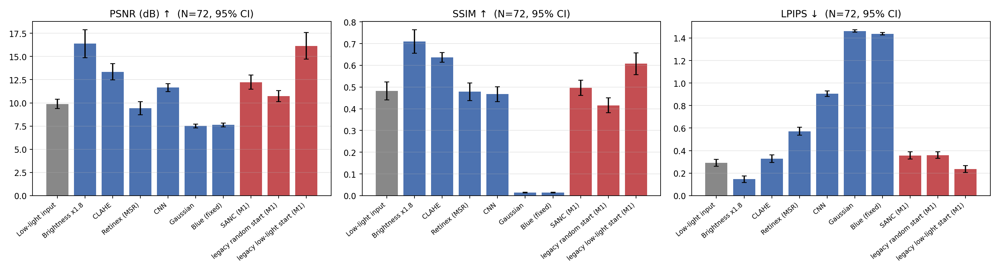

fig2_by_dataset.png


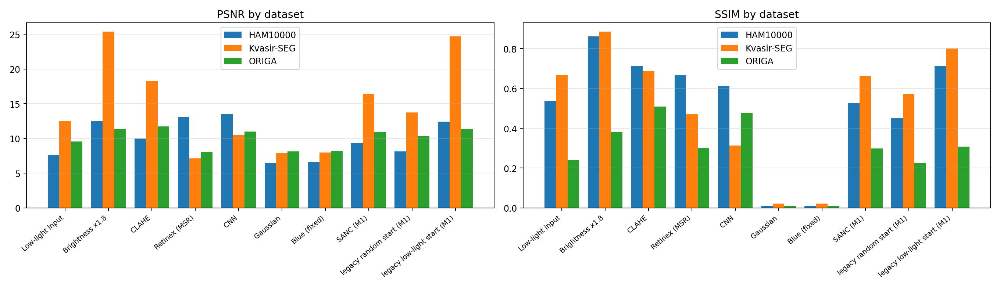

fig3_psnr_boxplot.png


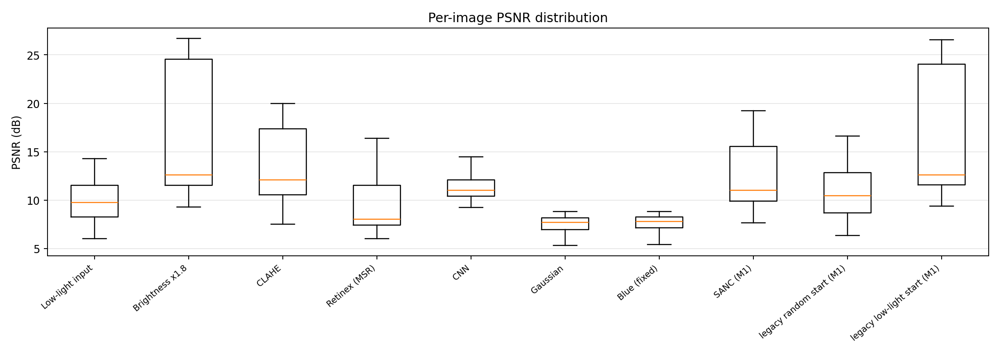

fig4_segmentation_boundary.png


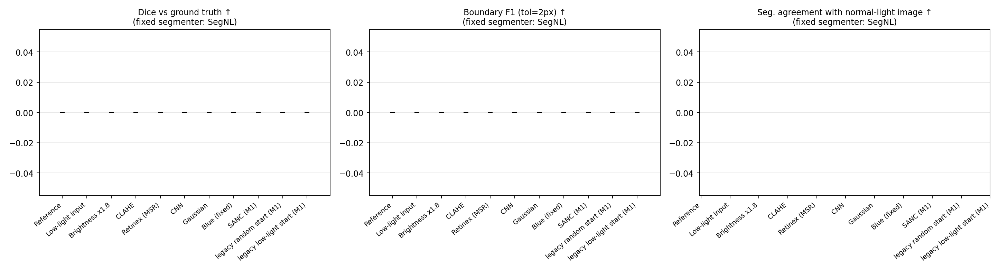

fig5_exposure_artifacts.png


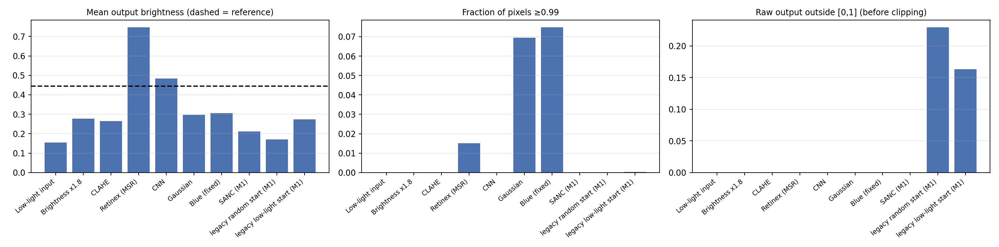

fig6_training_and_sampler_selection.png


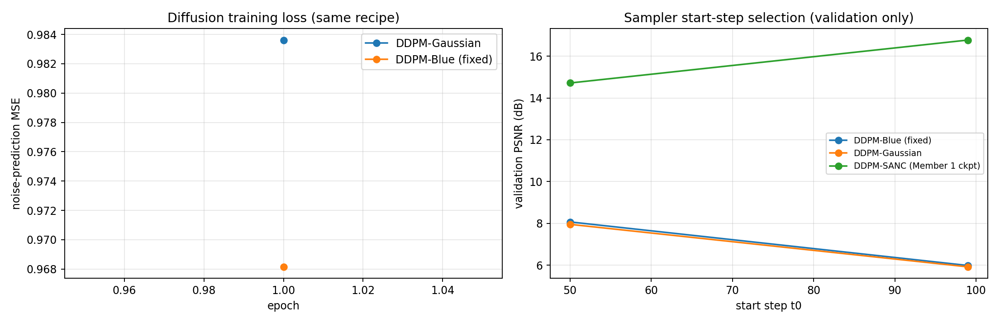

fig7_qualitative_grid.png


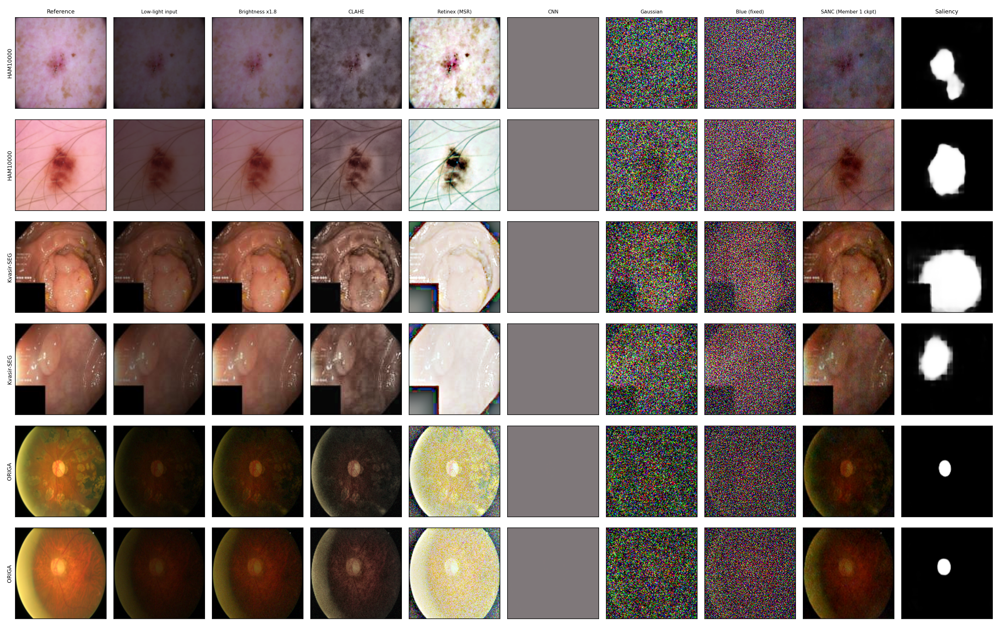

fig8_boundary_overlays.png


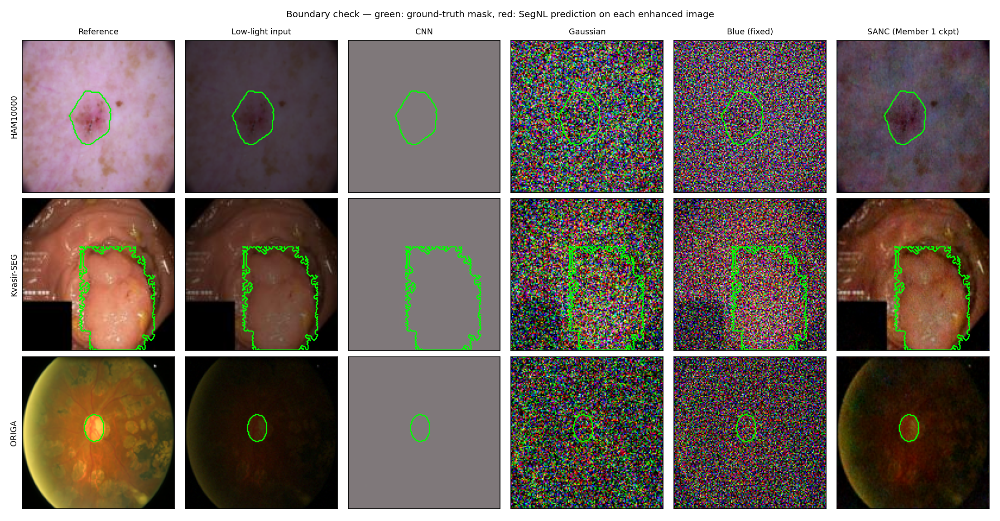

In [60]:
make_figures(C)
from IPython.display import Image as IPImage, display
for f in sorted((C["out"] / "figures").glob("*.png")):
    print(f.name); display(IPImage(filename=str(f)))

**Step 10 — summary file and export.** Everything is in `SANC/results/member3/` on Drive (per-image CSV, tables, figures, enhanced outputs, summary markdown).

In [61]:
summary_text = write_summary(C)
print(summary_text)
z = shutil.make_archive(str(C["out"].parent / "member3_results"), "zip", C["out"])
print("\nZipped:", z)

Wrote /content/member3_out/member3_results_summary.md
# Member 3 — automatically generated results summary

* Test images evaluated: **72** (held-out split; images with empty masks are excluded only from mask-based metrics).
* Primary SANC model in comparisons: **DDPM-SANC (Member 1 ckpt)**.
* Sampler: deterministic DDIM-style, start step and steps chosen on validation images: DDPM-SANC (Member 1 ckpt): t0=99, 25 steps; DDPM-Gaussian: t0=50, 25 steps; DDPM-Blue (fixed): t0=50, 25 steps.
* Metrics on outputs clipped to [0,1]; SSIM = skimage, RGB, data_range=1; LPIPS = AlexNet; boundary tolerance = 2 px; bootstrap resamples = 500.

## Overall results (mean ± std over test images)

|                                        |   N | PSNR             | SSIM            | LPIPS           | PSNR_roi         | SegNL_dice      | SegNL_bf1       | SegNL_cons   |
|:---------------------------------------|----:|:-----------------|:----------------|:----------------|:-----------------|:---------------

In [62]:
import shutil
shutil.copytree(C["out"], "/content/drive/MyDrive/SANC_member3_results", dirs_exist_ok=True)
print("copied")

copied
